<a href="https://colab.research.google.com/github/heisbaed/COU07506_LAB_WEEK_1_230141409381/blob/main/COU07506_Week03_230141409381.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COU 07506 — DIGITAL SIGNAL PROCESSING
## Week 3 — Lab 1B
### Convolution, Correlation and Difference Equations

**Task 3.1 — Convolution from the Definition**

Manual convolution: [1. 3. 6. 6. 4. 1.]
NumPy convolution: [1 3 6 6 4 1]
Results match: True

Pre-lab verification:
Manual: [ 2. -1.  3.  3. -1.  2.]
NumPy: [ 2 -1  3  3 -1  2]


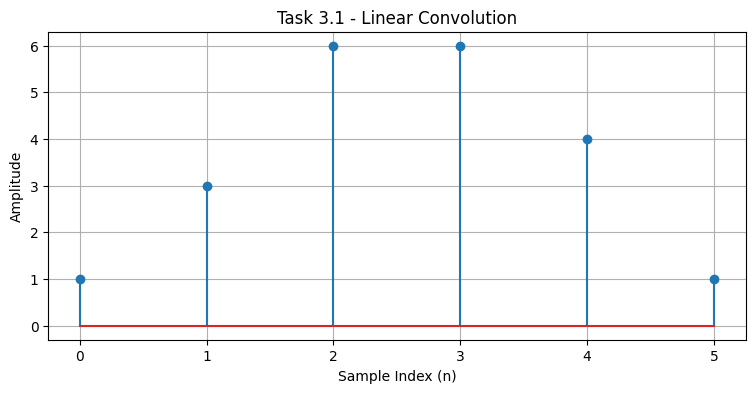

In [1]:

# WEEK 3 — TASK 3.1
# Convolution from the Definition

import numpy as np
import matplotlib.pyplot as plt
import time

# Define convolution function manually
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)

    for n in range(N):
        for k in range(len(x)):
            if 0 <= n-k < len(h):
                y[n] += x[k] * h[n-k]

    return y

# Example from laboratory manual
x = [1, 2, 3, 1]
h = [1, 1, 1]

manual_result = conv(x, h)
numpy_result = np.convolve(x, h)

print("Manual convolution:", manual_result)
print("NumPy convolution:", numpy_result)
print("Results match:",
      np.allclose(manual_result, numpy_result))

# Verify pre-lab example
x2 = [1, -1, 2]
h2 = [2, 1, 0, 1]

print("\nPre-lab verification:")
print("Manual:", conv(x2, h2))
print("NumPy:", np.convolve(x2, h2))

# Plot convolution output
n = np.arange(len(manual_result))

plt.figure(figsize=(9, 4))
plt.stem(n, manual_result)
plt.title("Task 3.1 - Linear Convolution")
plt.xlabel("Sample Index (n)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()


In [2]:

# TASK 3.1 — Execution Time Comparison

rng = np.random.default_rng(0)

x = rng.standard_normal(2000)
h = rng.standard_normal(2000)

# Manual convolution timing
start = time.perf_counter()
y_manual = conv(x, h)
manual_time = time.perf_counter() - start

# NumPy convolution timing
start = time.perf_counter()
y_numpy = np.convolve(x, h)
numpy_time = time.perf_counter() - start

print(f"Manual time: {manual_time:.6f} seconds")
print(f"NumPy time: {numpy_time:.6f} seconds")

print("Results match:",
      np.allclose(y_manual, y_numpy))

print(f"Speed-up: {manual_time/numpy_time:.2f}x")


Manual time: 3.603324 seconds
NumPy time: 0.001111 seconds
Results match: True
Speed-up: 3244.44x


### Task 3.1 — Observation and Discussion

The manual convolution function and NumPy's built-in convolution function produced matching results.

For the first example, both functions returned [1, 3, 6, 6, 4, 1].

The manual method calculates each output sample using nested loops, while `np.convolve()` uses optimized numerical routines.

The execution time comparison demonstrates that NumPy is generally more efficient for convolution of larger signals.

**Conclusion:** Linear convolution can be implemented directly from its mathematical definition, and its result can be verified using NumPy's built-in convolution function.

## Task 3.2 — Smoothing a Noisy Signal by Convolution

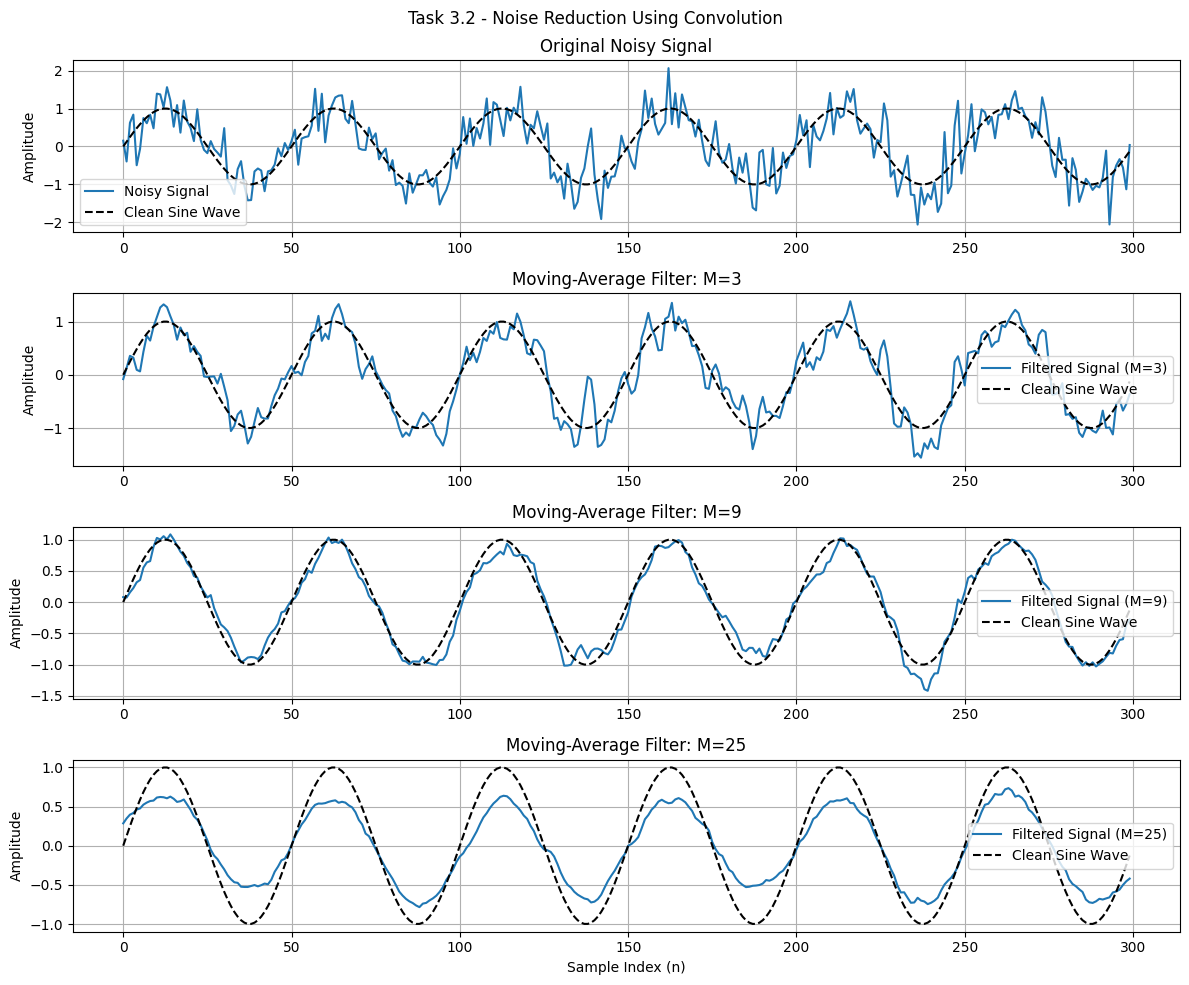

Task 3.2 completed successfully!


In [3]:

# WEEK 3 — TASK 3.2
# Smoothing a Noisy Signal by Convolution

import numpy as np
import matplotlib.pyplot as plt

# Generate the original sine wave
n = np.arange(300)
clean = np.sin(2 * np.pi * n / 50)

# Add Gaussian noise
rng = np.random.default_rng(42)
noise = 0.5 * rng.standard_normal(300)
x = clean + noise

# Moving-average filter lengths
M_values = [3, 9, 25]

# Plot original and filtered signals
fig, axes = plt.subplots(4, 1, figsize=(12, 10))

axes[0].plot(n, x, label="Noisy Signal")
axes[0].plot(n, clean, "k--", label="Clean Sine Wave")
axes[0].set_title("Original Noisy Signal")
axes[0].set_ylabel("Amplitude")
axes[0].legend()
axes[0].grid(True)

# Apply moving-average filters
for i, M in enumerate(M_values):

    h = np.ones(M) / M

    # Convolution
    y = np.convolve(x, h, mode="same")

    axes[i+1].plot(n, y,
                   label=f"Filtered Signal (M={M})")
    axes[i+1].plot(n, clean, "k--",
                   label="Clean Sine Wave")

    axes[i+1].set_title(
        f"Moving-Average Filter: M={M}"
    )
    axes[i+1].set_ylabel("Amplitude")
    axes[i+1].legend()
    axes[i+1].grid(True)

axes[-1].set_xlabel("Sample Index (n)")

plt.suptitle(
    "Task 3.2 - Noise Reduction Using Convolution"
)
plt.tight_layout()
plt.show()

print("Task 3.2 completed successfully!")


### Task 3.2 — Observation and Discussion

The original signal contains Gaussian noise, causing fluctuations around the sine wave.

**M = 3:** The moving-average filter slightly reduces noise while preserving most of the original signal shape.

**M = 9:** More noise is removed, producing a smoother waveform with relatively little distortion.

**M = 25:** The signal becomes smoother, but its amplitude is noticeably reduced because the longer filter averages over a larger portion of the sine wave.

**Trade-off:**

A shorter moving-average filter preserves the original signal more accurately but removes less noise. A longer filter provides stronger noise reduction but introduces greater signal distortion.

**Conclusion:** Convolution with a moving-average filter is useful for noise reduction, but the filter length must be chosen carefully to balance smoothing and signal preservation.

## Task 3.3 — Testing Linearity and Time-Invariance Numerically

In [4]:

# WEEK 3 - TASK 3.3
# Testing Linearity and Time-Invariance

import numpy as np

# Generate random signals
rng = np.random.default_rng(0)

x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)

# Constants for testing linearity
a, b = 2.0, -3.0

# Define the three systems
systems = {
    "x^2": lambda x: x**2,

    "n x(n)": lambda x: np.arange(len(x)) * x,

    "moving average": lambda x:
        np.convolve(x, np.ones(3)/3)[:len(x)]
}

# Test each system
for name, T in systems.items():

    # Test linearity
    linear = np.allclose(
        T(a*x1 + b*x2),
        a*T(x1) + b*T(x2)
    )

    # Delay input by 5 samples
    xd = np.concatenate(
        [np.zeros(5), x1]
    )[:50]

    # Delay original output by 5 samples
    yd = np.concatenate(
        [np.zeros(5), T(x1)]
    )[:50]

    # Test time-invariance
    tinv = np.allclose(T(xd), yd)

    # Display results
    print(
        f"{name:15s} "
        f"linear={linear} "
        f"time-invariant={tinv}"
    )

print("\nTask 3.3 Completed Successfully!")


x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True

Task 3.3 Completed Successfully!


### Task 3.3 — Observation and Discussion

Three systems were tested for linearity and time-invariance using Python.

**1. Squaring System — x²(n)**

The system is nonlinear because squaring the sum of two input signals does not generally equal the sum of their squared outputs.

However, it is time-invariant because delaying the input produces the same result as delaying the output.

**2. Time-Dependent System — nx(n)**

The system is linear because it satisfies the superposition principle.

However, it is time-varying because its output depends explicitly on the sample index n. Delaying the input changes the relationship between the input and output.

**3. Moving-Average Filter**

The moving-average filter is both linear and time-invariant because it satisfies superposition, and delaying its input produces an equally delayed output.

**Conclusion:**

Among the three systems tested, only the moving-average filter is a Linear Time-Invariant (LTI) system.

## Task 3.4 — Finding a Hidden Delay with Cross-Correlation

True delay: 37 samples
Estimated delay: 37 samples
Distance: 12.691 meters


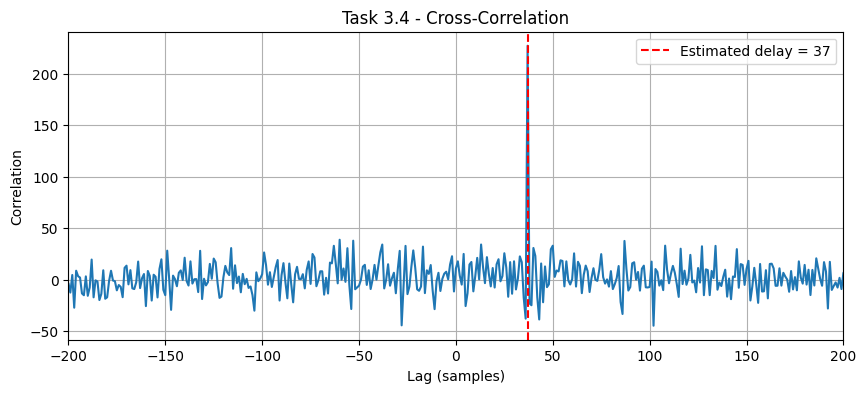

In [5]:

# WEEK 3 — TASK 3.4
# Finding a Hidden Delay with Cross-Correlation

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

rng = np.random.default_rng(1)

fs = 1000
x = rng.standard_normal(500)

true_delay = 37

# Create delayed signal with noise
y = np.concatenate([
    np.zeros(true_delay), 0.6*x
])[:500] + 0.5*rng.standard_normal(500)

# Cross-correlation
r = signal.correlate(y, x, mode="full")
lags = signal.correlation_lags(
    len(y), len(x), mode="full"
)

estimated_delay = lags[np.argmax(r)]

print("True delay:", true_delay, "samples")
print("Estimated delay:", estimated_delay, "samples")

# Convert delay to distance
speed_of_sound = 343
distance = estimated_delay / fs * speed_of_sound

print(f"Distance: {distance:.3f} meters")

# Plot cross-correlation
plt.figure(figsize=(10, 4))
plt.plot(lags, r)
plt.axvline(
    estimated_delay,
    color="red",
    linestyle="--",
    label=f"Estimated delay = {estimated_delay}"
)

plt.xlim(-200, 200)
plt.title("Task 3.4 - Cross-Correlation")
plt.xlabel("Lag (samples)")
plt.ylabel("Correlation")
plt.legend()
plt.grid(True)
plt.show()


In [6]:

# TASK 3.4 — Effect of Increasing Noise

rng = np.random.default_rng(1)

x = rng.standard_normal(500)
true_delay = 37
clean_y = np.concatenate([
    np.zeros(true_delay), 0.6*x
])[:500]

# Same noise pattern for fair comparison
noise = rng.standard_normal(500)

noise_levels = [0.5, 1, 2, 4]

for std in noise_levels:
    y = clean_y + std * noise

    r = signal.correlate(y, x, mode="full")
    lags = signal.correlation_lags(
        len(y), len(x), mode="full"
    )

    estimate = lags[np.argmax(r)]
    correct = estimate == true_delay

    print(
        f"Noise std = {std}: "
        f"Estimated delay = {estimate} samples, "
        f"Correct = {correct}"
    )


Noise std = 0.5: Estimated delay = 37 samples, Correct = True
Noise std = 1: Estimated delay = 37 samples, Correct = True
Noise std = 2: Estimated delay = 37 samples, Correct = True
Noise std = 4: Estimated delay = 87 samples, Correct = False


### Task 3.4 — Observation and Discussion

Cross-correlation was used to estimate the delay between a transmitted signal and a noisy received signal.

The original signal was delayed by 37 samples, and cross-correlation detected the delay by identifying the lag corresponding to the maximum correlation.

At a sampling rate of 1,000 Hz, the delay corresponds to 0.037 seconds.

Assuming one-way sound propagation at 343 m/s:

Distance = 343 × 0.037 = **12.691 meters**

**Effect of noise:**

As the noise standard deviation increases, the cross-correlation peak becomes more difficult to identify reliably.

The delay estimates obtained for noise standard deviations of 0.5, 1, 2 and 4 were:

Noise std = 0.5: Estimated delay = 37 samples, Correct = True
Noise std = 1: Estimated delay = 37 samples, Correct = True
Noise std = 2: Estimated delay = 37 samples, Correct = True
Noise std = 4: Estimated delay = 87 samples, Correct = False

**Conclusion:**

Cross-correlation is useful for estimating signal delays in noisy environments. However, sufficiently strong noise can reduce the accuracy of delay estimation.

## Task 3.5 — Difference Equation

n | Recursion | lfilter | Theory
----------------------------------------
0 | 1.000000 | 1.000000 | 1.000000
1 | 1.750000 | 1.750000 | 1.750000
2 | 1.187500 | 1.187500 | 1.187500
3 | 0.671875 | 0.671875 | 0.671875
4 | 0.355469 | 0.355469 | 0.355469
5 | 0.182617 | 0.182617 | 0.182617
6 | 0.092529 | 0.092529 | 0.092529
7 | 0.046570 | 0.046570 | 0.046570
8 | 0.023361 | 0.023361 | 0.023361
9 | 0.011700 | 0.011700 | 0.011700

Manual vs lfilter: True
Manual vs Theory: True


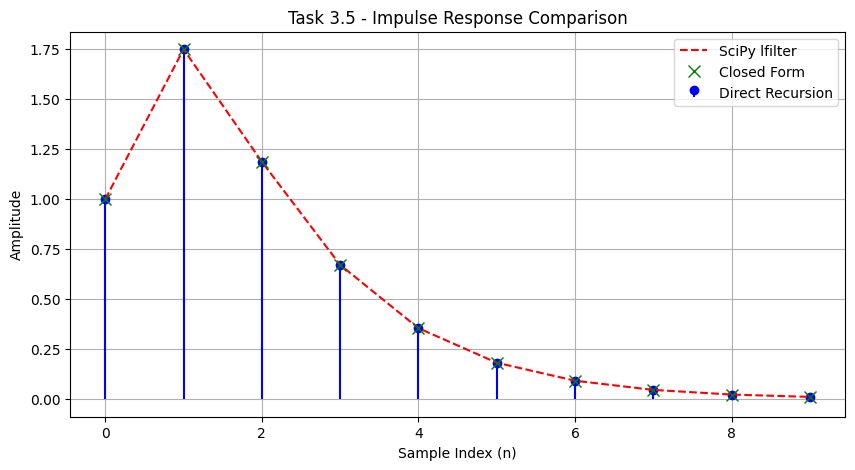

In [7]:

# WEEK 3 — TASK 3.5
# Difference Equation and Impulse Response

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Sample indices
n = np.arange(10)

# Unit impulse input
impulse = np.zeros(10)
impulse[0] = 1

# METHOD 1: Direct Recursion
h_manual = np.zeros(10)

for i in range(10):
    x0 = impulse[i]
    x1 = impulse[i-1] if i >= 1 else 0
    y1 = h_manual[i-1] if i >= 1 else 0
    y2 = h_manual[i-2] if i >= 2 else 0

    h_manual[i] = x0 + x1 + 0.75*y1 - 0.125*y2

# METHOD 2: Using scipy.signal.lfilter
b = [1, 1]
a = [1, -0.75, 0.125]

h_lfilter = signal.lfilter(b, a, impulse)

# METHOD 3: Closed-form expression
h_theory = 6*(0.5**n) - 5*(0.25**n)

# Print comparison
print("n | Recursion | lfilter | Theory")
print("----------------------------------------")

for i in range(10):
    print(
        f"{i} | {h_manual[i]:.6f} | "
        f"{h_lfilter[i]:.6f} | "
        f"{h_theory[i]:.6f}"
    )

# Verify the methods match
print("\nManual vs lfilter:",
      np.allclose(h_manual, h_lfilter))

print("Manual vs Theory:",
      np.allclose(h_manual, h_theory))

# Plot the impulse responses
plt.figure(figsize=(10, 5))

plt.stem(n, h_manual,
         linefmt="b-", markerfmt="bo",
         basefmt=" ", label="Direct Recursion")

plt.plot(n, h_lfilter, "r--",
         label="SciPy lfilter")

plt.plot(n, h_theory, "gx",
         markersize=8, label="Closed Form")

plt.title("Task 3.5 - Impulse Response Comparison")
plt.xlabel("Sample Index (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()


Final step response: 5.333333333333333
Theoretical H(1): 5.333333333333333
Results match: True


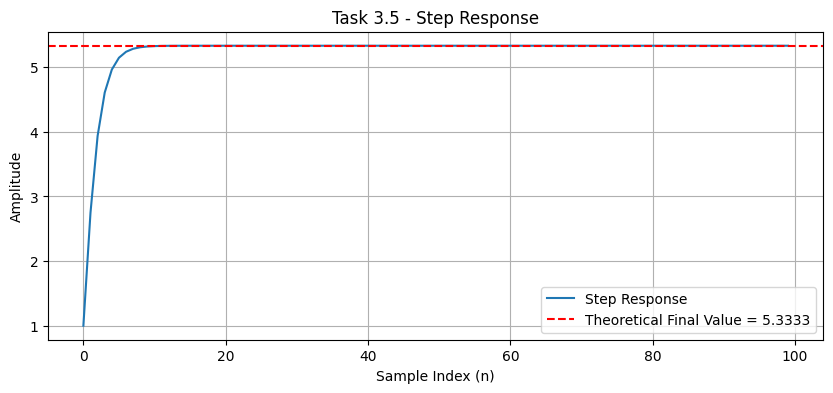

In [8]:

# TASK 3.5 — Step Response

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# System coefficients
b = [1, 1]
a = [1, -0.75, 0.125]

# Generate unit step input
n = np.arange(100)
step = np.ones(100)

# Calculate step response
y_step = signal.lfilter(b, a, step)

# Theoretical final value H(1)
H1 = sum(b) / sum(a)

print("Final step response:", y_step[-1])
print("Theoretical H(1):", H1)

print("Results match:",
      np.isclose(y_step[-1], H1))

# Plot step response
plt.figure(figsize=(10, 4))

plt.plot(n, y_step, label="Step Response")
plt.axhline(
    H1, color="red", linestyle="--",
    label=f"Theoretical Final Value = {H1:.4f}"
)

plt.title("Task 3.5 - Step Response")
plt.xlabel("Sample Index (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()


### Task 3.5 — Observation and Discussion

The impulse response was calculated using three methods: direct recursion, SciPy's `lfilter()` function, and the closed-form mathematical expression.

All three methods produced matching impulse-response values, confirming that the difference equation was implemented correctly.

The impulse response initially increased and then gradually decreased toward zero.

The step response approached a constant final value of approximately **5.3333**, agreeing with the theoretical value calculated using H(1).

**System Classification:**

The system is an Infinite Impulse Response (IIR) system because its output depends on previous output values.

The system is stable because its poles are at 0.5 and 0.25, both inside the unit circle.

**Conclusion:**

The difference equation can be solved using direct recursion or SciPy's filtering function. Both implementations agree with the theoretical impulse response and confirm that the system is stable.

# WEEK 3 — PRE-LAB AND ANALYSIS QUESTIONS

## A. Pre-Lab Questions

### Question 1: Convolve x(n) = {1, −1, 2} with h(n) = {2, 1, 0, 1} by hand.

**Answer:**

Given:

- x(n) = {1, −1, 2}
- h(n) = {2, 1, 0, 1}

Using the linear convolution formula:

y(n) = Σ x(k)h(n − k)

Calculating each output sample:

- y(0) = 1(2) = 2
- y(1) = 1(1) + (−1)(2) = −1
- y(2) = 1(0) + (−1)(1) + 2(2) = 3
- y(3) = 1(1) + (−1)(0) + 2(1) = 3
- y(4) = (−1)(1) + 2(0) = −1
- y(5) = 2(1) = 2

**Final result:**

y(n) = **{2, −1, 3, 3, −1, 2}**

This result agrees with the output obtained using the manual convolution function and NumPy's `np.convolve()`.

### Question 2: Is y(n) = nx(n) time-invariant? Show your test.

**Answer:**

The system is not time-invariant because its output explicitly depends on the sample index n.

Given:

T{x(n)} = nx(n)

If the input is delayed by k samples:

T{x(n − k)} = nx(n − k)

However, delaying the original output gives:

y(n − k) = (n − k)x(n − k)

These two expressions are generally different.

**Conclusion:** The system y(n) = nx(n) is time-varying.

---

## B. Analysis Questions

### Question 1: Why is np.convolve much faster than a double loop? What is the number of multiplications for lengths L and M?

**Answer:**

NumPy's `np.convolve()` is generally faster because it uses optimized compiled numerical routines, while the manually implemented convolution uses nested Python loops.

For two sequences of lengths L and M, direct linear convolution requires:

**Number of multiplications = L × M**

For example, if L = 2,000 and M = 2,000:

2,000 × 2,000 = **4,000,000 multiplications**

Both implementations calculate the same convolution, but NumPy usually performs the computation much faster.

### Question 2: Which of the three systems in Task 3.3 are LTI? Could you have predicted this without running code?

**Answer:**

The three systems were classified as follows:

| System | Linear | Time-Invariant | LTI |
|---|---|---|---|
| x²(n) | No | Yes | No |
| nx(n) | Yes | No | No |
| Moving average | Yes | Yes | Yes |

Only the moving-average filter is an LTI system.

The results can be predicted mathematically without running Python by checking the superposition principle and the effect of delaying an input signal.

### Question 3: Give two engineering applications of cross-correlation in Tanzania.

**Answer:**

**1. Water Pipeline Leak Detection**

Cross-correlation can be used to estimate the time difference between leak-generated sounds recorded by sensors installed at different points along a water pipeline.

The estimated time delay helps engineers locate underground leaks, reducing water losses in distribution networks such as those operated in Dar es Salaam.

**2. Radar Systems at Airports**

Cross-correlation can be used in radar signal processing to detect reflected signals and estimate their time delays.

This assists in determining distances to aircraft and supporting surveillance systems at airports such as Julius

Nyerere International Airport.

Question 4: Is the system in Task 3.5 FIR or IIR? Is it stable? Justify using the impulse response.

Answer:

The system is an Infinite Impulse Response (IIR) system because its current output depends on previous output values.

Its impulse response is:

h(n) = 6(0.5)ⁿ − 5(0.25)ⁿ, for n ≥ 0.

The impulse response continues indefinitely but decreases toward zero as n increases.

The system has two poles:

p₁ = 0.5

p₂ = 0.25

Both poles lie inside the unit circle, and the impulse response is absolutely summable.

Therefore, the system is BIBO stable.

C. AI-Use Statement

I used ChatGPT (OpenAI) to assist in understanding convolution, correlation, system properties, and difference equations.

The tool helped with Python code preparation, explanation of mathematical concepts, and interpretation of laboratory results.

I ran the Python code in Google Colab, checked the convolution outputs against NumPy's built-in function, and verified the numerical results of the system tests and impulse-response calculations.

I reviewed the explanations and compared them with the expected theoretical results.